In [1]:
import pandas as pd

# load dataset
data = pd.read_csv('Wholesale customers data.csv')

display(data.info())

# since no null value contain do no processing needed for null value. Now we will select the required columns for clustering.

# Select spending features
X = data[['Fresh', 'Milk', 'Grocery', 'Frozen',
          'Detergents_Paper', 'Delicassen']]


<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


None

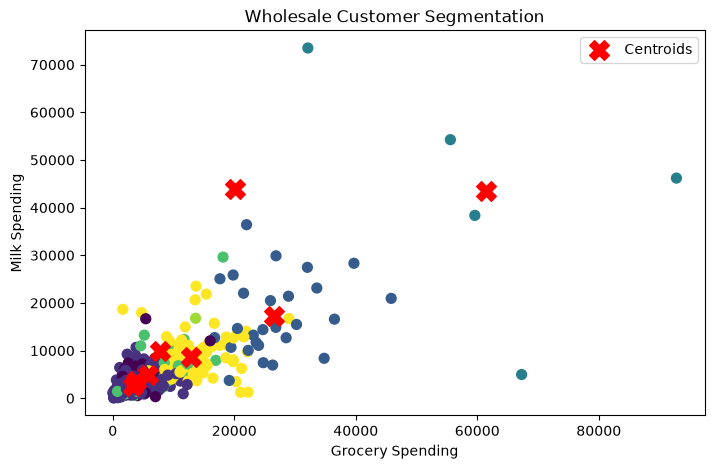

Cluster
1    219
7     99
5     44
0     42
2     28
3      5
6      2
4      1
Name: count, dtype: int64


In [6]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means with 5 clusters
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X_scaled)

# Visualize clusters using two spending features
# Visualize clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    data['Grocery'], data['Milk'],
    c=data['Cluster'], cmap='viridis', s=50
)

# Plot centroids (convert back to original scale)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centroids[:, 2], centroids[:, 1],
    color='red', marker='X', s=200,
    label='Centroids'
)

plt.title('Wholesale Customer Segmentation')
plt.xlabel('Grocery Spending')
plt.ylabel('Milk Spending')
plt.legend()
plt.show()

print(data['Cluster'].value_counts())

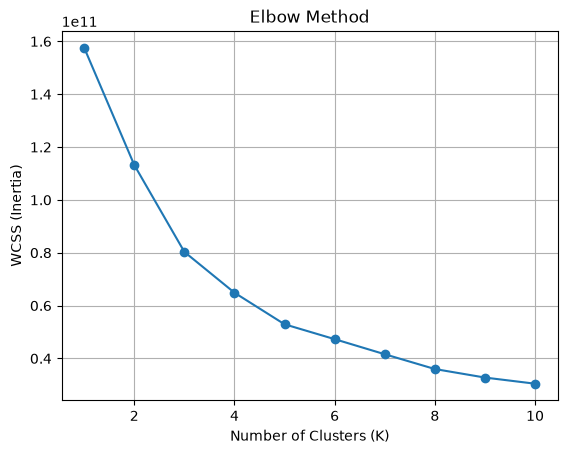

In [7]:
# finding j value for elbow method to find the optimal number of clusters

# Calculate WCSS for different numbers of clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()